# TrustXRay — 05. Out-of-distribution (OOD) detection

**Problem found during robustness testing:** a blank white image, a blank black image or a grayscale text document are classified as *pneumonia* with **30/30 votes**. Monte Carlo Dropout measures the model's doubt **on chest X-rays**, but it cannot tell that an image is **not** a chest X-ray.

**Solution:** Mahalanobis distance in feature space (Lee et al., 2018).
1. Extract the 512 internal features of ResNet18 for all **training** X-rays.
2. Model their distribution (mean + covariance).
3. For a new image, measure how far its features are from this distribution. **Too far → the app refuses to answer.**

The threshold is chosen on the **validation** set so that 99% of real X-rays are accepted.

> Runs on GPU or CPU. Needs `resnet18_baseline.pt` in `MyDrive/TrustXRay`.

In [1]:
!pip install -q medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 9.3 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, models, datasets
from PIL import Image, ImageDraw
from medmnist import PneumoniaMNIST, BreastMNIST
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
SIZE, DATA_DIR, FIG_DIR = 224, "./data", "./figures"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/TrustXRay"
except ImportError:
    SAVE_DIR = "./models"
MODEL_PATH = os.path.join(SAVE_DIR, "resnet18_baseline.pt")
assert os.path.exists(MODEL_PATH), "Run notebook 02 first"

model = models.resnet18(weights=None)
model.fc = nn.Sequential(nn.Dropout(p=0.3), nn.Linear(512, 1))
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE).eval()
feature_extractor = nn.Sequential(*list(model.children())[:-1]).eval()

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

Device: cuda
Mounted at /content/drive


## 1. Extract the features of real X-rays (train / validation / test)

In [3]:
import os, shutil, subprocess, hashlib

CACHE = os.path.join(SAVE_DIR, "data_cache")      # copy kept in Google Drive
os.makedirs(CACHE, exist_ok=True)
FILES = {
    "pneumoniamnist_224.npz": ("https://zenodo.org/records/10519652/files/pneumoniamnist_224.npz?download=1",
                               "d6a3c71de1b945ea11211b03746c1fe1"),
}

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for name, (url, expected) in FILES.items():
    local, cached = os.path.join(DATA_DIR, name), os.path.join(CACHE, name)
    if os.path.exists(local) and md5(local) == expected:
        print("already here:", name); continue
    if os.path.exists(cached) and md5(cached) == expected:
        shutil.copy(cached, local); print("copied from Drive:", name); continue
    for attempt in range(1, 6):
        print(f"downloading {name} from Zenodo (attempt {attempt}/5)...")
        subprocess.run(["wget", "-q", "-c", "--tries=3", "--timeout=60", "-O", local, url])
        if os.path.exists(local) and md5(local) == expected:
            shutil.copy(local, cached); print("ok, saved to Drive:", name); break
    else:
        raise RuntimeError("Zenodo download failed — use the manual method (step 2 below).")

@torch.no_grad()
def extract(loader):
    feats = []
    for batch in loader:
        feats.append(feature_extractor(batch[0].to(DEVICE)).flatten(1).cpu())
    return torch.cat(feats).numpy()

def pneumonia_loader(split):
    ds = PneumoniaMNIST(split=split, transform=eval_tf, download=False, size=SIZE, as_rgb=True, root=DATA_DIR)
    return DataLoader(ds, batch_size=64, shuffle=False, num_workers=2), ds

train_loader, train_ds = pneumonia_loader("train")
val_loader, val_ds = pneumonia_loader("val")
test_loader, test_ds = pneumonia_loader("test")
F_train, F_val, F_test = extract(train_loader), extract(val_loader), extract(test_loader)
print("features:", F_train.shape, F_val.shape, F_test.shape)

copied from Drive: pneumoniamnist_224.npz
features: (4708, 512) (524, 512) (624, 512)


## 2. Model the distribution and compute Mahalanobis distances

We use a **Ledoit-Wolf** covariance estimate (more stable than the plain covariance with 512 dimensions and ~4,700 images).

In [4]:
lw = LedoitWolf().fit(F_train)
MU = F_train.mean(axis=0)
PRECISION = lw.precision_

def mahalanobis(F):
    d = F - MU
    return np.sqrt(np.einsum("ij,jk,ik->i", d, PRECISION, d))

d_val, d_test = mahalanobis(F_val), mahalanobis(F_test)
OOD_THRESHOLD = float(np.percentile(d_val, 99))   # accept 99% of real validation X-rays
print(f"OOD threshold (99th percentile of validation): {OOD_THRESHOLD:.1f}")
print(f"Test X-rays accepted: {(d_test <= OOD_THRESHOLD).mean() * 100:.1f}%")

OOD threshold (99th percentile of validation): 18.7
Test X-rays accepted: 98.9%


## 3. Build out-of-distribution test sets

| OOD set | What it represents |
|---|---|
| Blank / uniform images | Empty uploads |
| Gaussian noise | Corrupted images |
| Grayscale text documents | Wrong file uploaded |
| Rotated chest X-rays (90°) | Wrong orientation |
| Inverted chest X-rays (negative) | Wrong export settings |
| Breast ultrasound (BreastMNIST) | Another medical imaging modality |
| Natural photos in grayscale (CIFAR-10) | Non-medical images |

In [5]:
rng = np.random.default_rng(0)
N = 200

def to_tensor_batch(gray_list):
    return torch.stack([eval_tf(Image.fromarray(g).convert("RGB")) for g in gray_list])

ood = {}
ood["blank / uniform"] = [np.full((SIZE, SIZE), v, np.uint8) for v in np.linspace(0, 255, N).astype(int)]
ood["gaussian noise"] = [rng.integers(0, 256, (SIZE, SIZE), dtype=np.uint8) for _ in range(N)]

def text_image(i):
    im = Image.new("L", (SIZE, SIZE), 255); d = ImageDraw.Draw(im)
    for k in range(12):
        d.text((5, 5 + k * 18), "Lorem ipsum dolor sit amet %d %d" % (i, k), fill=0)
    return np.array(im)
ood["text documents"] = [text_image(i) for i in range(N)]

test_imgs = test_ds.imgs[:N]
ood["rotated X-rays (90°)"] = [np.rot90(g).copy() for g in test_imgs]
ood["inverted X-rays"] = [255 - g for g in test_imgs]

breast = BreastMNIST(split="test", download=True, size=SIZE, root=DATA_DIR)
ood["breast ultrasound"] = list(breast.imgs[:N])

cifar = datasets.CIFAR10(root=DATA_DIR, train=False, download=True)
ood["natural photos (CIFAR-10)"] = [np.array(Image.fromarray(cifar.data[i]).convert("L").resize((SIZE, SIZE))) for i in range(N)]

d_ood = {}
for name, imgs in ood.items():
    loader = DataLoader(TensorDataset(to_tensor_batch(imgs)), batch_size=64)
    d_ood[name] = mahalanobis(extract(loader))
print("done")

100%|██████████| 30.9M/30.9M [00:42<00:00, 730kB/s]
100%|██████████| 170M/170M [50:18<00:00, 56.5kB/s]


done


## 4. Results: does the detector separate real X-rays from OOD images?

set                             rejected    AUROC vs test X-rays
real test X-rays                    1.1%                       —
blank / uniform                   100.0%                   1.000
gaussian noise                    100.0%                   1.000
text documents                    100.0%                   1.000
rotated X-rays (90°)               99.0%                   0.999
inverted X-rays                    41.0%                   0.975
breast ultrasound                  99.4%                   1.000
natural photos (CIFAR-10)          97.5%                   0.999


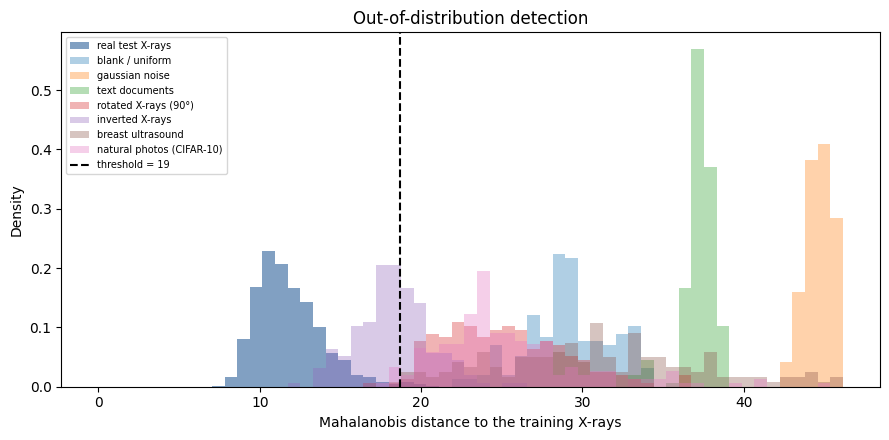

In [6]:
print(f"{'set':30s}{'rejected':>10s}{'AUROC vs test X-rays':>24s}")
print(f"{'real test X-rays':30s}{100 * (d_test > OOD_THRESHOLD).mean():9.1f}%{'—':>24s}")
for name, d in d_ood.items():
    auroc = roc_auc_score(np.r_[np.zeros(len(d_test)), np.ones(len(d))], np.r_[d_test, d])
    print(f"{name:30s}{100 * (d > OOD_THRESHOLD).mean():9.1f}%{auroc:24.3f}")

plt.figure(figsize=(9, 4.5))
bins = np.linspace(0, np.percentile(np.concatenate([d_test] + list(d_ood.values())), 99), 60)
plt.hist(d_test, bins=bins, alpha=0.7, density=True, label="real test X-rays", color="#4C78A8")
for name, d in d_ood.items():
    plt.hist(d, bins=bins, alpha=0.35, density=True, label=name, histtype="stepfilled")
plt.axvline(OOD_THRESHOLD, color="k", ls="--", label=f"threshold = {OOD_THRESHOLD:.0f}")
plt.xlabel("Mahalanobis distance to the training X-rays"); plt.ylabel("Density")
plt.title("Out-of-distribution detection"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ood_distances.png", dpi=150); plt.show()

## 5. Save the detector for the Streamlit app

In [7]:
out = os.path.join(SAVE_DIR, "ood_stats.npz")
np.savez_compressed(out, mu=MU.astype(np.float32), precision=PRECISION.astype(np.float32),
                    threshold=np.float32(OOD_THRESHOLD))
print("saved:", out, f"({os.path.getsize(out) / 1e6:.1f} MB)")

saved: /content/drive/MyDrive/TrustXRay/ood_stats.npz (1.0 MB)


## 6. Observations (fill in after running)

- **Real test X-rays accepted:** ...%
- **OOD sets rejected:** blank ...%, noise ...%, text ...%, rotated ...%, inverted ...%, ultrasound ...%, photos ...%
- **Hardest OOD set (lowest AUROC):** ...
- **Limitations:** the threshold accepts 99% of validation X-rays, so ~1% of real X-rays may be rejected; adult chest X-rays and other X-ray body parts were not tested.